In [ ]:
from google.colab.drive import mount
import numpy as np
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df=pd.read_csv("/content/drive/MyDrive/Un-normalized data/Mizo/Unnormal_Dataset_Mizo.csv")
df
# df = df.replace([' HS'],'HS')
# df=df.replace(['LLU'],'LU')
# df=df.replace([' LS'],'LS')
# #df=df.replace(['nan'],'LS')

df=df.replace(['FUU'],'FU')
df=df.replace(['FL'],'FU')
df=df.replace(['LLU'],'LU')
df=df.replace([' LS'],'LS')
df=df.replace([' HS'],'HS')
df['Tone_Stress'].unique()

array(['LU', 'LS', 'HS', 'FU', 'RS', 'RU', 'HU', 'FS'], dtype=object)

In [ ]:
df.columns

Index(['F1', 'F2', 'F3', 'F4', 'F5', 'intensityMin', 'intensityMax',
       'intensityAvg', 'intensityStdev', 'intensityRange', 'duration',
       'maxF0_Hz', 'minF0_Hz', 'meanF0_Hz', 'f0Range_Hz', 'Tone_Stress'],
      dtype='object')

In [ ]:
df ['Tone_Stress'] = df ['Tone_Stress'].fillna (0)
df ['duration'] = df ['duration'].fillna (0)
df ['maxF0_Hz'] = df ['maxF0_Hz'].fillna (0)
df ['minF0_Hz'] = df ['minF0_Hz'].fillna (0)
df ['meanF0_Hz'] = df ['meanF0_Hz'].fillna (0)
df ['f0Range_Hz'] = df ['f0Range_Hz'].fillna (0)
df ['intensityMin'] = df ['intensityMin'].fillna (0)
df ['intensityMax'] = df ['intensityMax'].fillna (0)
df ['intensityAvg'] = df ['intensityAvg'].fillna (0)
df ['intensityStdev'] = df ['intensityStdev'].fillna (0)
df ['intensityRange'] = df ['intensityRange'].fillna (0)
df ['F1'] = df ['F1'].fillna (0)
df ['F2'] = df ['F2'].fillna (0)
df ['F3'] = df ['F3'].fillna (0)
df ['F4'] = df ['F4'].fillna (0)
df ['F5'] = df ['F5'].fillna (0)

In [ ]:
from sklearn.model_selection import train_test_split
X = df.iloc[:,:-1]
y =  df.iloc[: ,-1:]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
np.any(np.isnan(X_train))
X_train = X_train.fillna(X_train.mean())
np.any(np.isnan(X_train))
df

,F1,F2,F3,F4,F5,intensityMin,intensityMax,intensityAvg,intensityStdev,intensityRange,duration,maxF0_Hz,minF0_Hz,meanF0_Hz,f0Range_Hz,Tone_Stress
0,291.293864,2493.336051,3580.536577,4291.369683,5032.585779,43.934131,78.641773,70.188385,9.935980,34.707642,0.317274,222.208207,201.344300,209.610492,20.863907,LU
1,369.634848,2802.340834,3721.716233,4483.359913,4512.342222,58.070088,77.340013,70.910850,6.106474,19.269925,0.381761,221.938183,168.477152,205.229762,53.461031,LS
2,335.008806,803.590521,3373.515319,4212.342222,4222.708412,53.160143,76.012597,69.167039,7.717322,22.852454,0.241421,225.579725,198.387978,212.839074,27.191747,HS
3,341.753396,2186.000908,3451.427304,4385.412380,4757.262289,45.785317,76.895944,63.911226,10.970667,31.110627,0.114913,237.483366,196.625182,216.448249,40.858184,FU
4,1007.679119,2016.156115,3058.228396,4201.018121,5035.777104,53.809848,76.650641,62.954339,8.529374,22.840793,0.149562,231.961027,222.775604,228.544465,9.185423,LU
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1481,467.580000,2486.510000,2969.060000,4185.610000,4250.460000,58.489889,83.185922,78.284571,6.913253,24.696033,0.166308,143.944458,99.720038,121.733054,44.224420,RU
1482,349.280000,2464.300000,3085.600000,4351.040000,4681.180000,66.076565,84.944189,81.645913,5.130019,18.867623,0.153866,109.393895,99.656551,104.434036,9.737344,LU
1483,389.160000,1364.530000,2303.590000,3650.200000,4741.310000,73.920651,84.606463,81.221648,3.139983,10.685812,0.209818,132.478460,100.916059,116.729323,31.562401,RS
1484,403.600000,2262.960000,3053.240000,3957.560000,4318.530000,64.086758,80.757688,74.367675,5.593426,16.670930,0.151702,106.203596,70.229770,86.926776,35.973826,FU


In [ ]:
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()
df.isnull().any().any()

False

USING DECISION TREE

In [ ]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
dt = DecisionTreeClassifier( max_depth=3, random_state=7)
dt.fit(X_train,y_train)
y_pred2= dt.predict(X_test)
acc1 = accuracy_score(y_test,y_pred2)*100
p=precision_score(y_test,y_pred2, average='micro')
recall = recall_score(y_test,y_pred2,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc1)
F1_score=f1_score(y_test,y_pred2,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.33557046979865773
Recall:  0.33557046979865773
Accuracy:  33.557046979865774
F1 Score:  0.33557046979865773


CONFUSION MATRIX FOR DECISION TREE

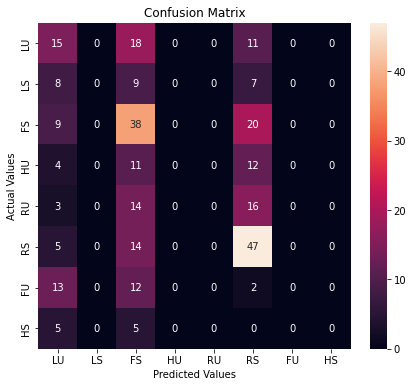

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, y_pred2)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

DECISION TREE K-CROSS VALIDATION

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
#dt = DecisionTreeClassifier( max_depth=3, random_state=7)

rf =DecisionTreeClassifier( max_depth=3, random_state=7)
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))


Cross-validation scores:[0.35714286 0.32352941 0.35714286 0.31223629 0.36708861]


USING GAUSSIAN NAIVE BAYES

In [ ]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()

model.fit(X_train,y_train)
pred = model.predict(X_test)
# print(pred)
from sklearn.metrics import accuracy_score
acc2 = accuracy_score(y_test,pred)*100
p=precision_score(y_test,pred, average='micro')
recall = recall_score(y_test,pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc2)
F1_score=f1_score(y_test,pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.21140939597315436
Recall:  0.21140939597315436
Accuracy:  21.140939597315437
F1 Score:  0.21140939597315436


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


CONFUSION MATRIX FOR NAIVE BAYES

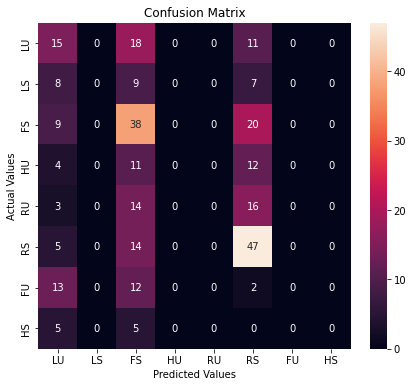

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, pred)
#cm_df = pd.DataFrame(cm,index = ['LS', 'LU', 'HS', 'HU'],columns = ['LS', 'LU', 'HS', 'HU'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score

rf =GaussianNB()
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.20588235 0.23529412 0.24789916 0.21940928 0.24050633]


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example usin

USING LOGISTIC REGRESSION

In [ ]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver = 'newton-cg',multi_class='auto',max_iter=1000)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
from sklearn.metrics import accuracy_score
acc3 = accuracy_score(y_test,y_pred)*100
p=precision_score(y_test,y_pred, average='micro')
recall = recall_score(y_test,y_pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc3)
F1_score=f1_score(y_test,y_pred,average='micro')
print('F1 Score: ',F1_score)

/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Precision:  0.3288590604026846
Recall:  0.3288590604026846
Accuracy:  32.88590604026846
F1 Score:  0.3288590604026846


/usr/local/lib/python3.7/dist-packages/sklearn/utils/optimize.py:212: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  ConvergenceWarning,


CONFUSION MATRIX FOR LOGISTIC REGRESSION

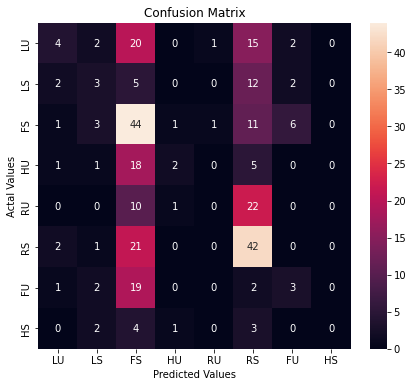

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

LOGISTIC REGRESSION K-CROSS VALIDATION

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression


rf =LogisticRegression(solver = 'newton-cg',multi_class='auto',max_iter=1000)
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/optimize.py:212: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  ConvergenceWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/optimize.py:212: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  ConvergenceWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed 

Cross-validation scores:[0.34033613 0.34033613 0.34453782 0.38396624 0.40084388]


/usr/local/lib/python3.7/dist-packages/sklearn/utils/optimize.py:212: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  ConvergenceWarning,


LOGISTIC REGRESSION WITH PIPE LINE

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=100000,solver='lbfgs'))
pipe.fit(X_train, y_train)  # apply scaling on train
pred=pipe.predict(X_test)
# print(pred)
pipe.score(X_test, y_test)
acc4=accuracy_score(y_test,pred)*100
p=precision_score(y_test,pred, average='micro')
recall = recall_score(y_test,pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc4)
F1_score=f1_score(y_test,pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.3629032258064516
Recall:  0.3629032258064516
Accuracy:  36.29032258064516
F1 Score:  0.3629032258064516


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


CONFUSION MATRIX FOR LOGISTIC REGRESSION WITH PIPE LINE

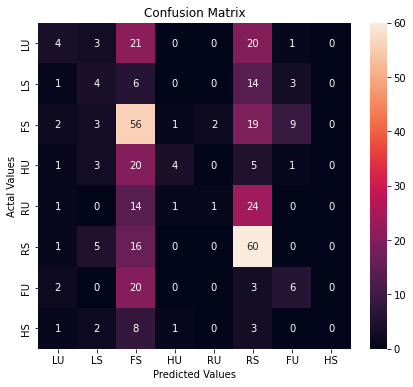

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, pred)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

LOGISTIC REGRESSION WITH PIPE LINE K-CROSS VALIDATION

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


rf =make_pipeline(StandardScaler(), LogisticRegression(max_iter=100000,solver='lbfgs'))
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example usin

Cross-validation scores:[0.34080717 0.34080717 0.3632287  0.38565022 0.4009009 ]


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


KNN

In [ ]:
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, MaxAbsScaler

x_data = df.drop(['Tone_Stress'],axis=1)
y_data = df['Tone_Stress']
#MinMaxScaler = preprocessing.MinMaxScaler()
RobustScaler = preprocessing.RobustScaler()
#X_data_minmax = MinMaxScaler.fit_transform(x_data)
X_data_minmax = RobustScaler.fit_transform(x_data)
data = pd.DataFrame(X_data_minmax)

data.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,-0.446721,1.400523,1.145797,0.544838,1.166228,-1.913826,-1.214980,-1.744454,1.592626,1.692531,1.657783,2.293836,2.810376,2.456978,-0.110402
1,-0.150306,1.819736,1.383021,0.831607,-1.157767,-0.793281,-1.586028,-1.589210,0.516788,0.380569,2.543569,2.287390,1.938290,2.347020,0.972710
2,-0.281319,-0.891877,0.797940,0.426797,-2.451598,-1.182488,-1.964388,-1.963920,0.969330,0.685027,0.615860,2.374310,2.731934,2.538017,0.099855
3,-0.255800,0.983576,0.928855,0.685306,-0.063677,-1.767084,-1.712603,-3.093287,1.883305,1.386842,-1.121848,2.658438,2.685161,2.628610,0.553953
4,2.263831,0.753155,0.268164,0.409882,1.180484,-1.130987,-1.782523,-3.298903,1.197463,0.684036,-0.645907,2.526625,3.379027,2.932231,-0.498445


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
X_train, X_test, y_train, y_test = train_test_split(data, y_data,test_size=0.2, random_state = 1)
knn_clf=KNeighborsClassifier()
knn_clf.fit(X_train,y_train)
ypred=knn_clf.predict(X_test)

result = confusion_matrix(y_test, ypred)
print("Confusion Matrix:")
print(result)
result1 = classification_report(y_test, ypred)
print("Classification Report:")
print (result1)
result2= accuracy_score(y_test,ypred)
acc5=result2*100
print("Accuracy:",acc5)
p=precision_score(y_test,ypred, average='micro')
recall = recall_score(y_test,ypred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc5)
F1_score=f1_score(y_test,ypred,average='micro')
print('F1 Score: ',F1_score)

Confusion Matrix:
[[ 7  1  5  3  1  4  1  0]
 [ 6  8  3  5  0  5  0  1]
 [12  3 42 10  4 10  4  0]
 [ 7  2 10  5  5  5  0  0]
 [ 5  0 14  0  4  9  1  0]
 [10  5 14  1  7 27  0  0]
 [ 7  1  8  2  0  1  2  1]
 [ 3  1  4  0  1  1  0  0]]
Classification Report:
              precision    recall  f1-score   support

          FS       0.12      0.32      0.18        22
          FU       0.38      0.29      0.33        28
          HS       0.42      0.49      0.45        85
          HU       0.19      0.15      0.17        34
          LS       0.18      0.12      0.15        33
          LU       0.44      0.42      0.43        64
          RS       0.25      0.09      0.13        22
          RU       0.00      0.00      0.00        10

    accuracy                           0.32       298
   macro avg       0.25      0.23      0.23       298
weighted avg       0.32      0.32      0.31       298

Accuracy: 31.879194630872483
Precision:  0.3187919463087248
Recall:  0.3187919463087248
Acc

CONFUSION MATRIX FOR KNN

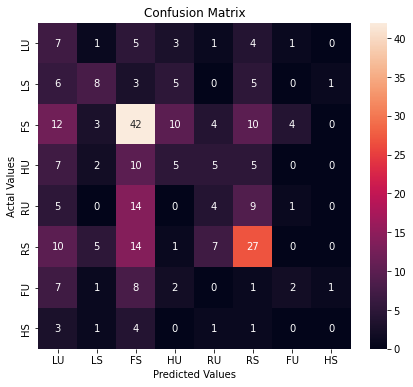

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, ypred)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

KNN K-CROSS VALIDATION

In [ ]:
#from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

rf =KNeighborsClassifier()
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.25630252 0.26470588 0.28991597 0.30801688 0.24472574]


SUPPORT VECTOR MACHINE

In [ ]:
from sklearn.svm import SVC
svc1 = SVC(C=1,kernel='rbf',gamma=1,max_iter=10000,random_state=101)     
svc1.fit(X_train,y_train)
y_pred = svc1.predict(X_test)
from sklearn.metrics import accuracy_score
acc6= accuracy_score(y_test,y_pred)*100
p=precision_score(y_test,y_pred, average='micro')
recall = recall_score(y_test,y_pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc6)
F1_score=f1_score(y_test,y_pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.3523489932885906
Recall:  0.3523489932885906
Accuracy:  35.23489932885906
F1 Score:  0.3523489932885906


CONFUSION MATRIX FOR SVM

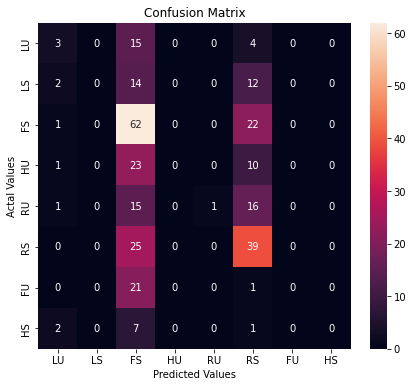

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

SVM K-CROSS VALIDATION

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

rf =SVC(C=1,kernel='rbf',gamma=1,max_iter=10000,random_state=101)
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.32773109 0.27731092 0.3487395  0.35864979 0.32911392]


ENSEMBLE LEARNING

In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
bagging = BaggingClassifier(RandomForestClassifier(n_estimators = 200, criterion = 'entropy', random_state =42,max_depth=15),max_samples=0.5, max_features=0.5)
bagging.fit(X_train, y_train)
pred=bagging.predict(X_test)
acc7=accuracy_score(y_test,pred)*100
p=precision_score(y_test,pred, average='micro')
recall = recall_score(y_test,pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc7)
F1_score=f1_score(y_test,pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.3926174496644295
Recall:  0.3926174496644295
Accuracy:  39.261744966442954
F1 Score:  0.39261744966442946


CONFUSION MATRIX FOR ENSEMBLE LEARNING

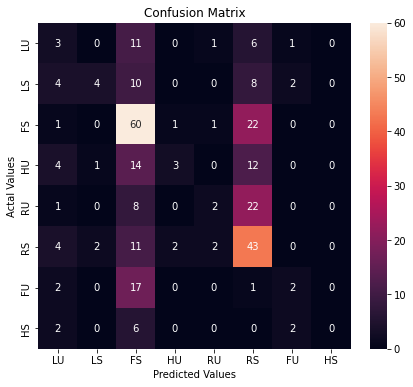

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, pred)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

ENSEMBLE LEARNING K-CROSS VALIDATION

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf = BaggingClassifier(RandomForestClassifier(n_estimators = 200, criterion = 'entropy', random_state =42,max_depth=15),max_samples=0.5, max_features=0.5)   
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.37394958 0.34453782 0.35294118 0.37552743 0.35864979]


RANDOM FOREST

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
# from sklearn.externals import joblib
from sklearn.metrics import accuracy_score

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
classifier = RandomForestClassifier(n_estimators = 200, criterion = 'entropy', random_state =42,max_depth=15)
classifier.fit(X_train, y_train)
# Predicting the Test set results
y_pred = classifier.predict(X_test)
acc8=accuracy_score(y_test,y_pred)*100
p=precision_score(y_test,y_pred, average='micro')
recall = recall_score(y_test,y_pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc8)
F1_score=f1_score(y_test,y_pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.40268456375838924
Recall:  0.40268456375838924
Accuracy:  40.26845637583892
F1 Score:  0.40268456375838924


CONFUSION MATRIX FOR RANDOM FOREST

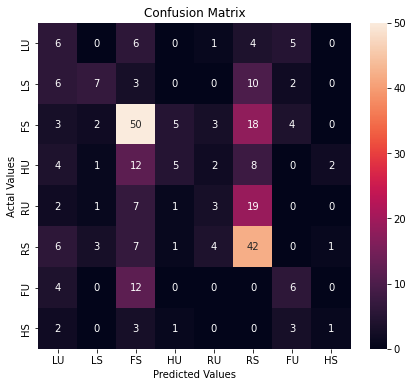

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

RANDOM FOREST K-CROSS VALIDATION



In [ ]:
#from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100,random_state=1, n_jobs=-1)    
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    
from sklearn.model_selection import cross_val_score
scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.36134454 0.37394958 0.3697479  0.39240506 0.38396624]


Chart

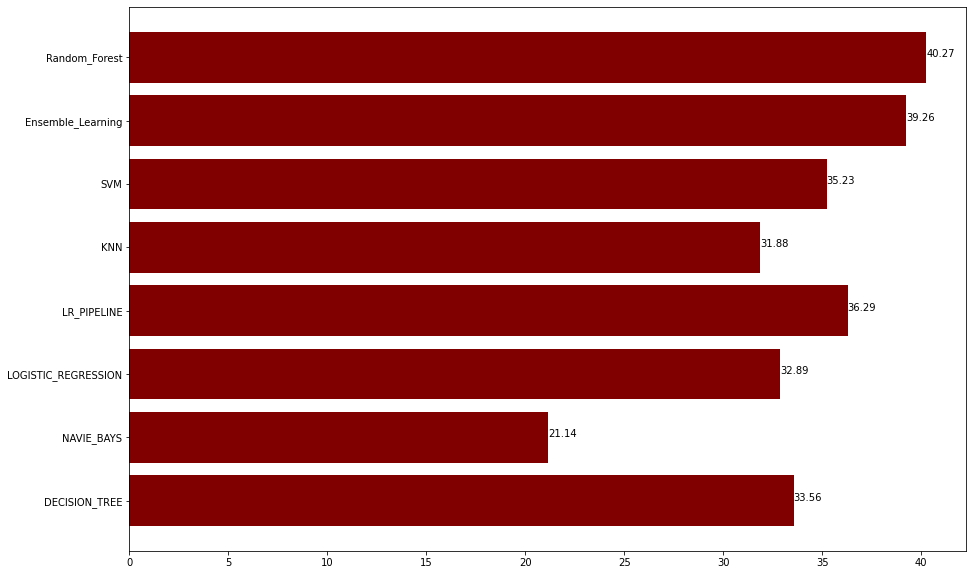

In [ ]:

import matplotlib.pyplot as plt
Model = ["DECISION_TREE",  "NAVIE_BAYS", "LOGISTIC_REGRESSION","LR_PIPELINE","KNN","SVM","Ensemble_Learning","Random_Forest"]
#acc = [round(acc1,2),round(acc2,2), round(acc3,2),round(acc4,2),round(acc5,2),round(acc6,2),round(acc7,2),round(acc8,2)]
acc = [round(acc1,2),round(acc2,2), round(acc3,2),round(acc4,2),round(acc5,2),round(acc6,2),round(acc7,2),round(acc8,2)]
fig = plt.figure(figsize = (15,10 ))
plt.barh(Model,acc,color="maroon")
for index, value in enumerate(acc):
  plt.text(value, index,str(value))
plt.show() 